In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100

study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    0.5 * study_hours
    + 0.3 * attendance
    + 0.2 * previous_mark
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_mark": previous_mark,
    "final_score": final_score
})

# Introduce the dirty records described in the task
df.loc[0:5, "study_hours"] = np.nan
df.loc[99, "study_hours"] = 50
df.loc[98, "attendance"] = -10

# Display the first five rows
df.head()


,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473


In [2]:

# Replace impossible attendance with a missing value
df.loc[df["attendance"] < 0, "attendance"] = np.nan

# Fill missing numerical values with their respective medians
df = df.fillna(df.median(numeric_only=True))

print(df.isnull().sum())
print(df.loc[[0, 98, 99]])


study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64
    study_hours  attendance  previous_mark  final_score
0      4.812342   70.846293      75.366810    35.178989
98     5.010227   85.996514      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470


In [3]:

X = df.drop(columns=["final_score"])
y = df["final_score"]

print("Feature matrix shape:", X.shape)
print("Numerical columns:", X.select_dtypes(include=np.number).columns.tolist())
print("Target variable:", y.name)


Feature matrix shape: (100, 3)
Numerical columns: ['study_hours', 'attendance', 'previous_mark']
Target variable: final_score


In [4]:

# Calculate the mean, median, and standard deviation
summary = df.agg(["mean", "median", "std"])

print(summary.round(2))


        study_hours  attendance  previous_mark  final_score
mean           5.19       85.23          70.97        42.69
median         4.81       86.00          71.47        42.76
std            4.86        9.54          16.26         6.09


part B
The mean study time is approximately 4.90 hours, and the median is 4.81 hours, suggesting that the typical study time is close to five hours.
The standard deviation of attendance is approximately 9.54, indicating that students' attendance rates vary around the average of 85.23.
The standard deviation of final scores is approximately 6.09, suggesting that most scores are relatively close to the mean score of 42.69.

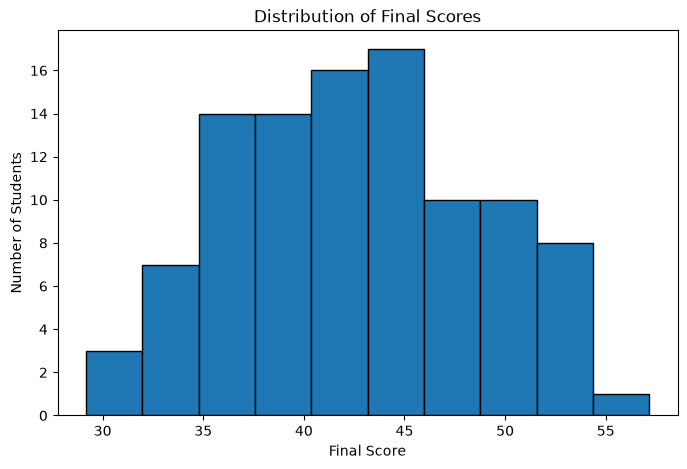

In [5]:

plt.figure(figsize=(8, 5))

plt.hist(df["final_score"], bins=10, edgecolor="black")

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()


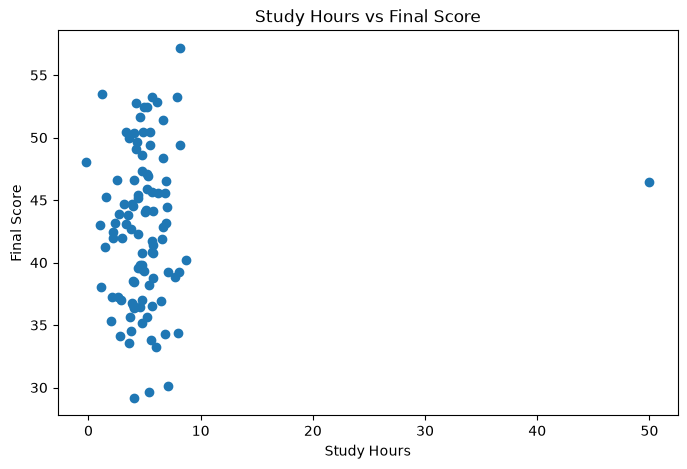

In [6]:

plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["final_score"])

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.show()


In [7]:

correlation = df["study_hours"].corr(df["final_score"])

print("Pearson correlation:", round(correlation, 3))


Pearson correlation: 0.076


part D
No. Correlation does not guarantee a specific outcome. Students who study the same number of hours may earn different scores.

In [8]:

# Select student row 10, excluding the target
x = df.iloc[10][
    ["study_hours", "attendance", "previous_mark"]
].to_numpy()

# Define weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate the predicted score
y_pred = np.dot(w, x) + b

print("Student feature vector:", x)
print("Weight vector:", w)
print("Predicted score:", round(y_pred, 2))


Student feature vector: [ 4.07316461 65.81228785 78.56335766]
Weight vector: [0.5 0.2 0.4]
Predicted score: 51.62
